# Proyecto Integrador M4 — Predicción de Fuga de Clientes (Churn) en FinanceGuard
### Avance 1: Comprensión del problema, EDA, preparación de datos y Regresión Logística (modelo baseline)

**Contexto:** FinanceGuard es un banco digital con clientes activos que atraviesa una tasa de abandono (churn) elevada. El objetivo de este proyecto integrador es construir un modelo de Machine Learning que prediga qué clientes tienen mayor probabilidad de abandonar el banco, para que el equipo de retención pueda actuar de forma proactiva.

**Dataset:** `Churn_Modelling.csv` — 10.000 clientes, con variables demográficas (edad, género, geografía, antigüedad) y financieras (saldo, productos contratados, salario estimado, score crediticio), más la variable objetivo `Exited` (1 = abandonó, 0 = activo).

En este notebook cubrimos los tres bloques del Avance 1:
1. Comprensión del problema y análisis exploratorio (EDA) básico
2. Preparación de datos para regresión logística
3. Implementación, interpretación y evaluación de la Regresión Logística (modelo baseline)


## 0. Importación de librerías

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                              classification_report, roc_curve, roc_auc_score,
                              precision_recall_curve, RocCurveDisplay)

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)


## 1. Comprensión del problema y análisis exploratorio básico

### 1.1 ¿Qué es el churn bancario?

El **churn** (o fuga/abandono de clientes) es la proporción de clientes que dejan de operar con la entidad en un período determinado: cierran su cuenta, dejan de usar sus productos o migran a la competencia.

En un banco digital como FinanceGuard, el churn tiene un impacto directo en el negocio:
- **Pérdida de ingresos recurrentes** (comisiones, intereses, uso de productos).
- **Costo de adquisición hundido**: conseguir un cliente nuevo suele costar varias veces más que retener uno existente.
- **Riesgo reputacional**: una fuga alta puede ser síntoma de problemas de producto, servicio o competitividad.

Por eso, anticipar **qué clientes tienen mayor probabilidad de irse** permite al equipo de retención actuar con ofertas, contacto proactivo o ajustes de producto antes de que el cliente se vaya, en lugar de reaccionar después del hecho.


In [6]:
df = pd.read_csv("../data/Churn_Modelling.csv")
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()


Filas: 10,000 | Columnas: 14


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### 1.2 Carga y exploración inicial del dataset

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [8]:
# Duplicados y unicidad del identificador de cliente
print("Filas duplicadas:", df.duplicated().sum())
print("CustomerId únicos:", df["CustomerId"].nunique(), "de", len(df))


Filas duplicadas: 0
CustomerId únicos: 10000 de 10000


In [9]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


**Observaciones iniciales:**
- El dataset no tiene valores nulos y `CustomerId` es único por fila, por lo que no hay clientes duplicados.
- `RowNumber`, `CustomerId` y `Surname` son identificadores/atributos sin poder predictivo real sobre el churn y se descartarán en la etapa de preparación de datos.
- El resto de las variables se agrupan en demográficas y financieras, descritas a continuación.


### 1.3 Variables demográficas: edad, género, ubicación (geografía), antigüedad

C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\2578641414.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Gender", data=df, ax=axes[0, 1], palette="Set2")
C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\2578641414.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Geography", data=df, ax=axes[1, 0], palette="Set2")


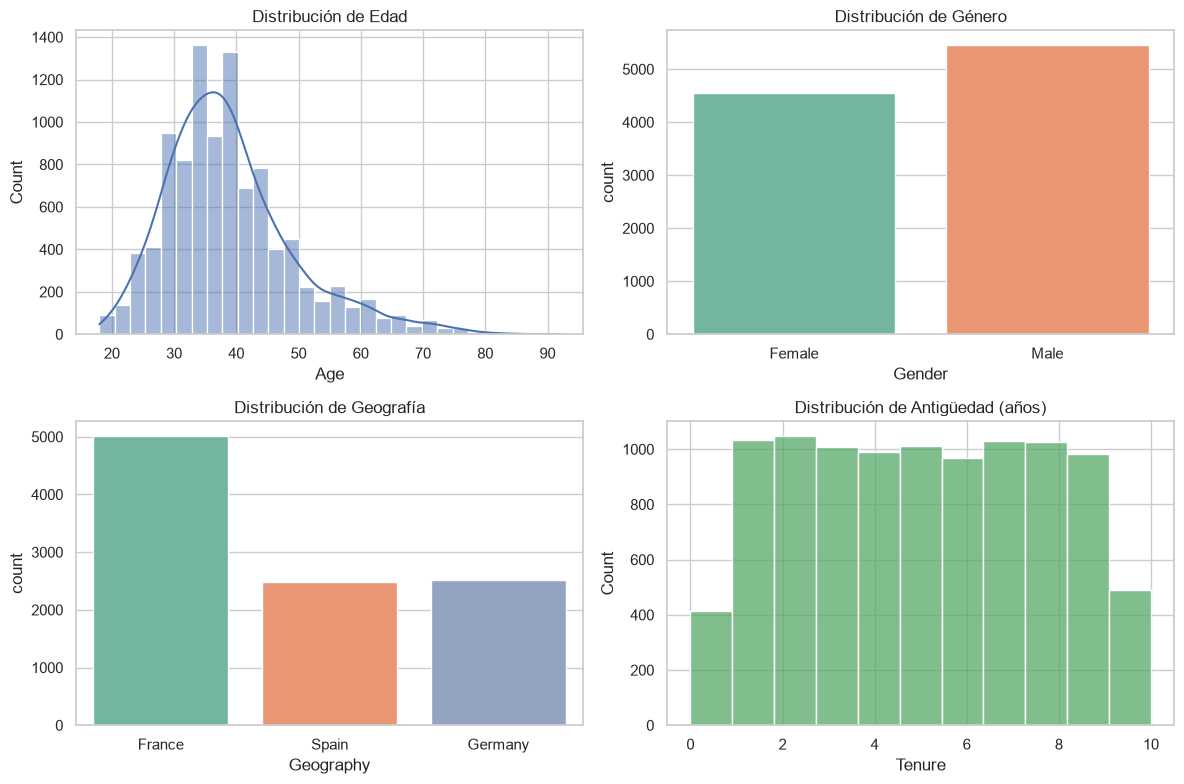

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Age"], bins=30, kde=True, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Distribución de Edad")

sns.countplot(x="Gender", data=df, ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Distribución de Género")

sns.countplot(x="Geography", data=df, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Distribución de Geografía")

sns.histplot(df["Tenure"], bins=11, ax=axes[1, 1], color="#55A868")
axes[1, 1].set_title("Distribución de Antigüedad (años)")

plt.tight_layout()
plt.show()


### 1.4 Variables financieras: saldo promedio, productos contratados, transacciones (proxies disponibles)

El dataset no incluye una variable de "transacciones" explícita; las variables financieras disponibles son `Balance` (saldo), `NumOfProducts` (productos contratados), `EstimatedSalary` (salario estimado), `CreditScore` (score crediticio), `HasCrCard` (tiene tarjeta de crédito) e `IsActiveMember` (miembro activo).


C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\204586375.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="NumOfProducts", data=df, ax=axes[0, 1], palette="Set2")


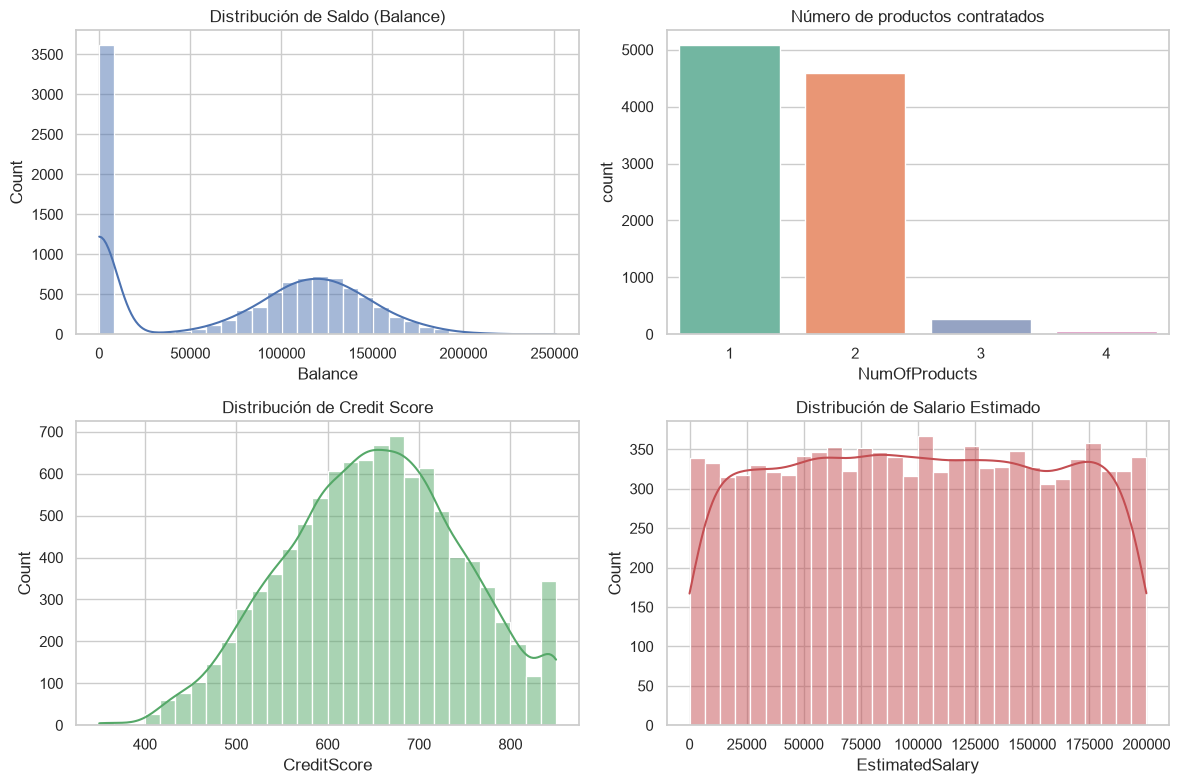

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Balance"], bins=30, kde=True, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Distribución de Saldo (Balance)")

sns.countplot(x="NumOfProducts", data=df, ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Número de productos contratados")

sns.histplot(df["CreditScore"], bins=30, kde=True, ax=axes[1, 0], color="#55A868")
axes[1, 0].set_title("Distribución de Credit Score")

sns.histplot(df["EstimatedSalary"], bins=30, kde=True, ax=axes[1, 1], color="#C44E52")
axes[1, 1].set_title("Distribución de Salario Estimado")

plt.tight_layout()
plt.show()


In [12]:
# Nota: ~36% de los clientes tiene saldo en 0. Se investiga si esto es relevante para el churn más adelante.
print("Clientes con Balance = 0:", (df['Balance'] == 0).sum(),
      f"({(df['Balance'] == 0).mean():.1%})")


Clientes con Balance = 0: 3617 (36.2%)


### 1.5 Variable objetivo y análisis de desbalanceo de clases

`Exited` es la variable objetivo (churn): 1 = el cliente abandonó el banco, 0 = el cliente sigue activo.


Exited
0    7963
1    2037
Name: count, dtype: int64

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\2673325322.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Exited", data=df, palette=["#4C72B0", "#C44E52"], ax=ax)
C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\2673325322.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Activo (0)", "Abandonó (1)"])


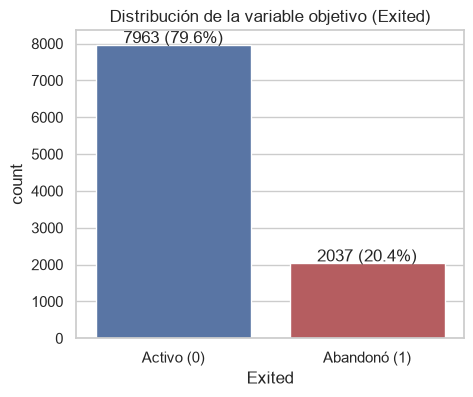

In [13]:
churn_counts = df["Exited"].value_counts()
churn_pct = df["Exited"].value_counts(normalize=True) * 100

print(churn_counts)
print()
print(churn_pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Exited", data=df, palette=["#4C72B0", "#C44E52"], ax=ax)
ax.set_xticklabels(["Activo (0)", "Abandonó (1)"])
ax.set_title("Distribución de la variable objetivo (Exited)")
for i, v in enumerate(churn_counts.sort_index()):
    ax.text(i, v + 50, f"{v} ({churn_pct.sort_index()[i]:.1f}%)", ha="center")
plt.show()


**Desbalanceo de clases:** aproximadamente el **80% de los clientes permanece activo y el 20% abandona**, un desbalanceo típico (80-20) en problemas de churn. Esto es relevante porque:
- Un modelo que prediga siempre "no churn" tendría ~80% de *accuracy* sin ser útil en absoluto.
- Es necesario prestar atención a métricas más informativas que el *accuracy*, como **Precision, Recall, F1-Score y ROC-AUC**, que se calculan más adelante en la sección de evaluación.
- En avances posteriores (con modelos de boosting) se abordarán técnicas específicas para el desbalanceo (ponderación de clases, PR-AUC, resampling).


### 1.6 Análisis bivariado: variables vs. churn

C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\4124722728.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Geography", y="Exited", data=df, ax=axes[0, 0], palette="Set2", errorbar=None)
C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\4124722728.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Gender", y="Exited", data=df, ax=axes[0, 1], palette="Set2", errorbar=None)
C:\Users\Julián\AppData\Local\Temp\ipykernel_28432\4124722728.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Exited", y="Age", data=df, ax=axes[1, 0]

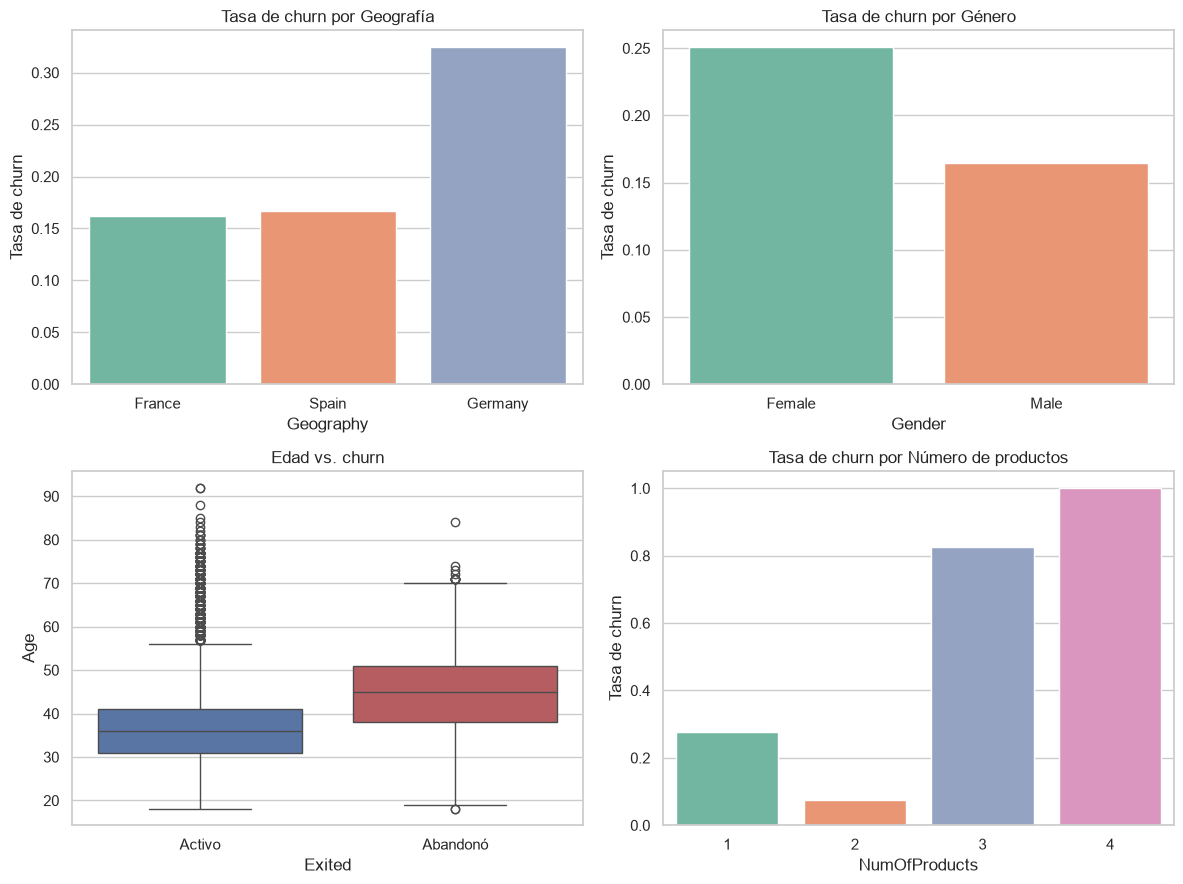

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.barplot(x="Geography", y="Exited", data=df, ax=axes[0, 0], palette="Set2", errorbar=None)
axes[0, 0].set_title("Tasa de churn por Geografía")
axes[0, 0].set_ylabel("Tasa de churn")

sns.barplot(x="Gender", y="Exited", data=df, ax=axes[0, 1], palette="Set2", errorbar=None)
axes[0, 1].set_title("Tasa de churn por Género")
axes[0, 1].set_ylabel("Tasa de churn")

sns.boxplot(x="Exited", y="Age", data=df, ax=axes[1, 0], palette=["#4C72B0", "#C44E52"])
axes[1, 0].set_xticklabels(["Activo", "Abandonó"])
axes[1, 0].set_title("Edad vs. churn")

sns.barplot(x="NumOfProducts", y="Exited", data=df, ax=axes[1, 1], palette="Set2", errorbar=None)
axes[1, 1].set_title("Tasa de churn por Número de productos")
axes[1, 1].set_ylabel("Tasa de churn")

plt.tight_layout()
plt.show()


**Patrones observados:**
- **Geografía**: Alemania muestra una tasa de churn notablemente más alta que Francia y España.
- **Género**: las clientas mujeres presentan una tasa de churn mayor que los clientes hombres.
- **Edad**: los clientes que abandonan tienden a ser de mayor edad en promedio.
- **Número de productos**: los clientes con 3 o 4 productos muestran tasas de churn muy elevadas (posible señal de clientes insatisfechos con productos que no terminan de adoptar, o un segmento de riesgo particular) mientras que 1-2 productos es lo más común y con menor churn relativo.

Estos patrones se retomarán en el Avance 3 (clustering) para perfilar segmentos de clientes.


### 1.7 Matriz de correlación y multicolinealidad

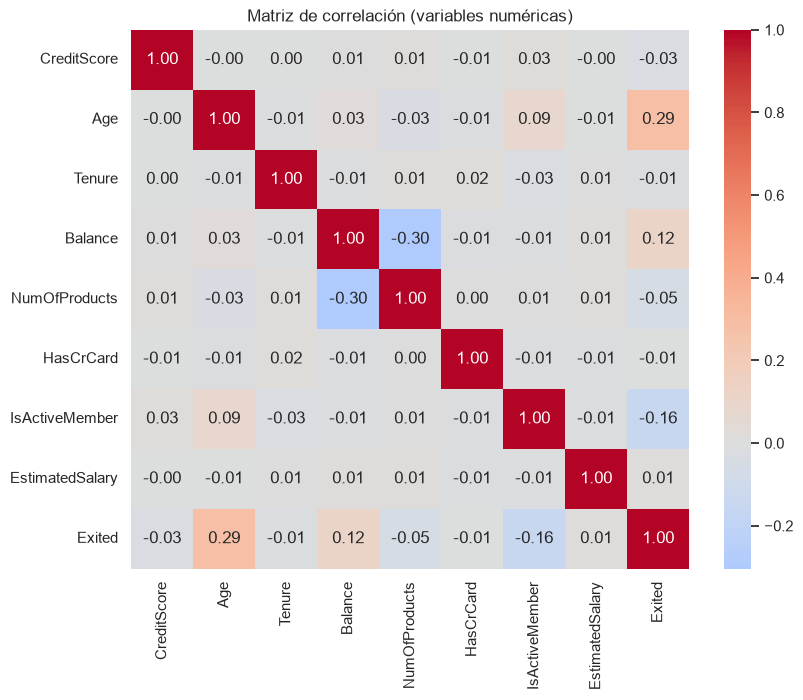

In [15]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
            "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]

corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriz de correlación (variables numéricas)")
plt.show()


In [16]:
# VIF (Variance Inflation Factor) para detectar multicolinealidad entre predictores numéricos
X_vif = sm.add_constant(df[["CreditScore", "Age", "Tenure", "Balance",
                             "NumOfProducts", "HasCrCard", "IsActiveMember",
                             "EstimatedSalary"]])

vif_data = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data


,variable,VIF
0,const,80.234130
1,CreditScore,1.000984
2,Age,1.009028
3,Tenure,1.001666
4,Balance,1.103281
5,NumOfProducts,1.103382
6,HasCrCard,1.001088
7,IsActiveMember,1.009289
8,EstimatedSalary,1.000853


**Interpretación:** ninguna variable numérica muestra correlación fuerte con otra (todas por debajo de ~0.3 en valor absoluto) y los valores de VIF están cercanos a 1, muy por debajo del umbral habitual de preocupación (VIF > 5-10). **No hay evidencia de multicolinealidad relevante** entre los predictores, por lo que se pueden usar todos en la regresión logística sin riesgo de inestabilidad en los coeficientes por este motivo.


## 2. Preparación de datos para regresión logística

### 2.1 Tratamiento de valores faltantes básico

Ya se verificó en la sección 1.2 que el dataset no contiene valores nulos. De todas formas, se deja el chequeo explícito como parte del pipeline de preparación, y se descartan las columnas sin poder predictivo (`RowNumber`, `CustomerId`, `Surname`).


In [17]:
print("Valores nulos por columna:")
print(df.isnull().sum())

df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df_model.head()


Valores nulos por columna:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### 2.2 Encoding de variables categóricas (One-Hot, Label Encoding)

- `Geography` (3 categorías, sin orden natural) → **One-Hot Encoding**.
- `Gender` (2 categorías) → **Label/Binary Encoding** (Female=0, Male=1), ya que al ser binaria es equivalente a un one-hot con una sola columna.


In [18]:
df_model = pd.get_dummies(df_model, columns=["Geography"], drop_first=True)
df_model["Gender"] = df_model["Gender"].map({"Female": 0, "Male": 1})

df_model.head()


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


### 2.3 Split básico: train (80%) / test (20%)

El split se hace **antes** de escalar, y de forma **estratificada** por la variable objetivo para preservar la proporción 80-20 de churn en ambos conjuntos.


In [19]:
X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de churn - train:", y_train.mean().round(3),
      "| test:", y_test.mean().round(3))


Train: (8000, 11) | Test: (2000, 11)
Proporción de churn - train: 0.204 | test: 0.204


### 2.4 Escalamiento de variables numéricas (StandardScaler)

Se ajusta (`fit`) el `StandardScaler` **solo con el set de entrenamiento** para evitar fuga de información (*data leakage*) del test set, y luego se aplica (`transform`) a ambos conjuntos.


In [20]:
numeric_features = ["CreditScore", "Age", "Tenure", "Balance",
                     "NumOfProducts", "EstimatedSalary"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

X_train_scaled.head()


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
2151,1.058568,1,1.715086,0.684723,-1.226059,-0.910256,1,0,1.042084,False,False
8392,0.913626,1,-0.659935,-0.696202,0.413288,-0.910256,1,0,-0.623556,True,False
5006,1.079274,0,-0.184931,-1.731895,0.601687,0.808830,1,1,0.308128,True,False
4117,-0.929207,1,-0.184931,-0.005739,-1.226059,0.808830,1,0,-0.290199,False,False
7182,0.427035,1,0.955079,0.339492,0.548318,0.808830,0,1,0.135042,True,False


## 3. Implementación de Regresión Logística

### 3.1 Interpretación de la función sigmoide

La regresión logística modela la probabilidad de que un cliente abandone (`Exited=1`) aplicando la función **sigmoide** a una combinación lineal de las variables:

$$P(Exited=1 \mid X) = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$

La sigmoide comprime cualquier valor real $z$ al rango $(0,1)$, lo que permite interpretar la salida como una probabilidad.


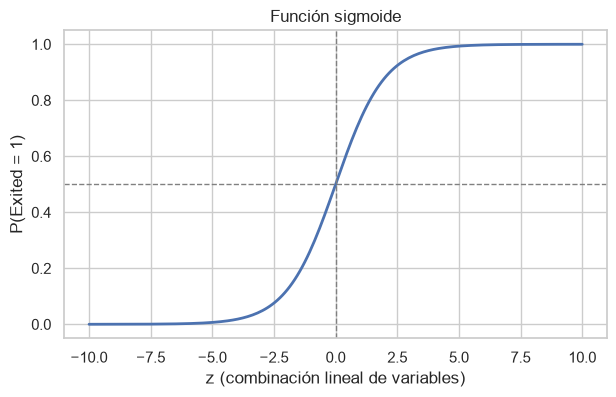

In [21]:
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z, sigmoid, color="#4C72B0", linewidth=2)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("z (combinación lineal de variables)")
ax.set_ylabel("P(Exited = 1)")
ax.set_title("Función sigmoide")
plt.show()


### 3.2 Regresión Logística Simple con scikit-learn

In [22]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Modelo entrenado. Features:", list(X_train_scaled.columns))


Modelo entrenado. Features: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']


### 3.3 Análisis de coeficientes: pesos, odds ratios e intervalos de confianza

Los coeficientes de la regresión logística se interpretan en la escala del **log-odds**. Exponenciando cada coeficiente se obtiene el **odds ratio**: cuánto se multiplican las chances (odds) de churn por cada unidad de aumento de esa variable (o al pasar de 0 a 1, en variables binarias/dummy), manteniendo el resto constante.


In [23]:
coefs = pd.DataFrame({
    "variable": X_train_scaled.columns,
    "coeficiente": log_reg.coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coeficiente"])
coefs = coefs.sort_values("odds_ratio", ascending=False).reset_index(drop=True)
coefs


,variable,coeficiente,odds_ratio
0,Geography_Germany,0.819585,2.269557
1,Age,0.738453,2.092695
2,Balance,0.161093,1.174794
3,EstimatedSalary,0.047666,1.048820
4,Geography_Spain,0.042508,1.043424
5,Tenure,-0.020096,0.980105
6,NumOfProducts,-0.070423,0.931999
7,HasCrCard,-0.070516,0.931913
8,CreditScore,-0.085893,0.917692
9,Gender,-0.523155,0.592648


In [24]:
# Intervalos de confianza de los coeficientes con statsmodels (Logit)
X_train_sm = sm.add_constant(X_train_scaled.astype(float))
logit_sm = sm.Logit(y_train, X_train_sm).fit(disp=0)

ci = logit_sm.conf_int()
ci.columns = ["IC 2.5%", "IC 97.5%"]
summary_df = pd.DataFrame({
    "coeficiente": logit_sm.params,
    "p_valor": logit_sm.pvalues
}).join(ci)
summary_df["odds_ratio"] = np.exp(summary_df["coeficiente"])
summary_df.round(4)


,coeficiente,p_valor,IC 2.5%,IC 97.5%,odds_ratio
const,-0.9946,0.0000,-1.1433,-0.8458,0.3699
CreditScore,-0.0861,0.0044,-0.1453,-0.0269,0.9175
Gender,-0.5248,0.0000,-0.6441,-0.4056,0.5917
Age,0.7397,0.0000,0.6811,0.7984,2.0953
Tenure,-0.0201,0.5042,-0.0793,0.0390,0.9801
Balance,0.1605,0.0000,0.0900,0.2309,1.1741
NumOfProducts,-0.0706,0.0218,-0.1309,-0.0103,0.9318
HasCrCard,-0.0710,0.2839,-0.2009,0.0589,0.9315
IsActiveMember,-1.0327,0.0000,-1.1583,-0.9070,0.3561
EstimatedSalary,0.0478,0.1162,-0.0118,0.1075,1.0490


**Interpretación (resumen):**
- **NumOfProducts** y **Age** son los predictores con mayor efecto sobre la probabilidad de churn: a mayor edad y (paradójicamente) mayor número de productos, mayor riesgo de fuga — consistente con lo observado en el análisis bivariado (clientes con 3-4 productos abandonan mucho más).
- **IsActiveMember** tiene un odds ratio menor a 1: ser miembro activo **reduce** las chances de churn, como es esperable.
- **Geography_Germany** tiene un odds ratio mayor a 1: ser cliente en Alemania (respecto a Francia, la categoría base) aumenta las chances de churn, en línea con el patrón visto en la sección 1.6.
- Las variables cuyo intervalo de confianza del coeficiente incluye el 0 (o cuyo p-valor es alto) no aportan evidencia estadísticamente significativa de asociación con el churn en este modelo — es el caso, por ejemplo, de `EstimatedSalary` y `Tenure`.


### 3.4 Evaluación específica: matriz de confusión, curva ROC/AUC, Precision/Recall/F1

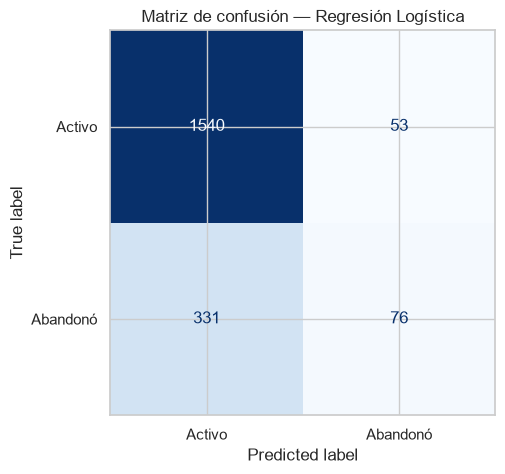

In [25]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Activo", "Abandonó"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión — Regresión Logística")
plt.show()


In [26]:
print(classification_report(y_test, y_pred, target_names=["Activo (0)", "Abandonó (1)"]))


              precision    recall  f1-score   support

  Activo (0)       0.82      0.97      0.89      1593
Abandonó (1)       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



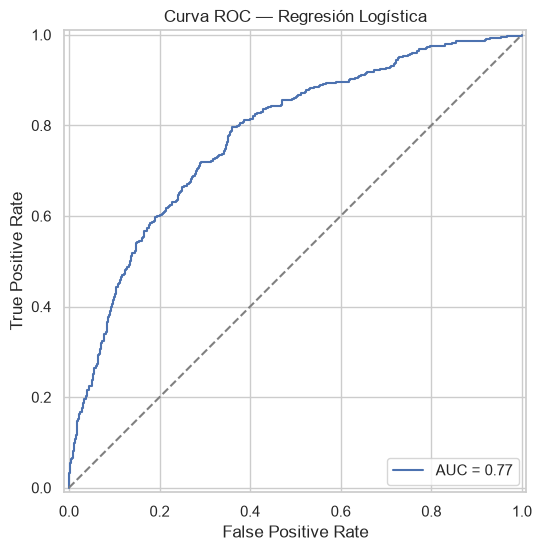

AUC: 0.7748


In [28]:
auc = roc_auc_score(y_test, y_proba)
fpr, tpr, _ = roc_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6, 6))
disp = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc).plot(ax=ax)
disp.line_.set_color("#4C72B0")  # coloreamos la línea después de graficarla
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_title("Curva ROC — Regresión Logística")
plt.show()

print(f"AUC: {auc:.4f}")

**Lectura de resultados:**
- El **Recall de la clase 1 (abandonó)** es notablemente más bajo que su Precision, lo cual es esperable dado el desbalanceo de clases 80-20: el modelo, al optimizar por defecto un umbral de 0.5, tiende a favorecer la clase mayoritaria y **deja pasar** una parte relevante de los clientes que efectivamente abandonan (falsos negativos).
- El **AUC-ROC** obtenido indica una capacidad de discriminación entre clientes que abandonan y que no muy por encima del azar (0.5), aceptable para un modelo baseline lineal.
- Este modelo de regresión logística funciona como **línea base (baseline)**: en el Avance 2 se compararán estos resultados con Random Forest, Gradient Boosting (XGBoost, LightGBM, CatBoost) y ensambles, que suelen capturar mejor relaciones no lineales como la observada entre `NumOfProducts` y el churn.


## Conclusiones del Avance 1

- El dataset de FinanceGuard (10.000 clientes) no presenta valores nulos ni duplicados, y muestra el desbalanceo de clases típico de problemas de churn (~80% activos / ~20% abandono).
- Los patrones más relevantes detectados en el EDA son: mayor churn en clientes de Alemania, en mujeres, en clientes de mayor edad y, sorprendentemente, en clientes con 3-4 productos contratados.
- No se detectó multicolinealidad relevante entre los predictores (VIF cercano a 1).
- La Regresión Logística, entrenada como modelo baseline, confirma cuantitativamente (vía odds ratios) los patrones detectados en el EDA, y expone la principal limitación de un modelo lineal simple frente a datos desbalanceados: buena Precision pero Recall más bajo para la clase de interés (churn).
- Este modelo y sus métricas servirán como punto de comparación para los modelos de ensamble y boosting del Avance 2.
